<a href="https://colab.research.google.com/github/Sankar-s-r/Deepfake_Detection/blob/New/Copy_of_FADID_PV_Lite_140k.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# FADID-PV Lite: Fast Deepfake Detection on 140k Real and Fake Faces
### A lightweight rebuild of the FADID-PV architecture, tuned specifically for this dataset

This is a faster, lighter variant of the full FADID-PV notebook, rebuilt around the
properties of the **140k Real and Fake Faces** dataset (70k real FFHQ photos + 70k
StyleGAN-generated faces, pre-aligned, with a built-in train/valid/test split). It keeps
every architectural idea from the original report but strips out work that dataset doesn't
need, instead of just shrinking numbers:

| Change | Why |
|---|---|
| Single shared `vit_small_patch16_224` backbone (not two copies of a giant ViT) | 140k doesn't need a billion-parameter foundation model to separate StyleGAN from FFHQ; a small ViT with LayerNorm-only fine-tuning is plenty, and halves memory/compute by reusing one backbone for both the spatial and frequency-masked passes |
| No MediaPipe face-mesh, no RetinaFace-style alignment | 140k images are already aligned — eyes sit at predictable fixed coordinates, so we skip per-image landmark detection, the single slowest step in the original pipeline |
| Adversarial DID loss **off by default** (`alpha_mi = 0`) | With only one fake generator, "generator id" ≈ the label itself, so training the model to *not* predict generator id fights the main classification objective. The module is still here, ready for when you add a second generator |
| Dataset's own train/valid/test split, no `group_split()` | 140k has no video grouping to protect against; the dataset authors already split it safely |
| `max_train_samples` cap | Run on a few thousand images first to prove the pipeline works end-to-end in minutes before committing to a full 100k-image run |

> ⚠️ Known limitation, inherited from the dataset itself: 140k has exactly one fake
> generator (StyleGAN). A model trained and evaluated only on this will **not** tell you
> anything about generalization to other generators or to face-swap-style forgery — see
> the note at the end of this notebook on adding a second dataset once this pipeline runs
> end-to-end.


## 1. Setup

Notably lighter than the original: no `mediapipe`, no heavyweight foundation model
download — just `timm`'s `vit_small_patch16_224`, a ~90MB download instead of several GB.


In [ ]:

!pip install -q torch torchvision timm albumentations opencv-python-headless \
     scikit-learn pandas matplotlib tqdm kaggle

import os, glob, random, math
from dataclasses import dataclass, field
from typing import Optional, Tuple, Dict

import numpy as np
import pandas as pd
import cv2
cv2.setNumThreads(0)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


## 2. Download the dataset (Kaggle API)

Needs a `kaggle.json` API token uploaded to this Colab session first
(kaggle.com → Account → Create New API Token).


In [ ]:
import os
from tqdm import tqdm
import zipfile

# Set up Kaggle credentials
!mkdir -p ~/.kaggle && cp /content/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

# Download dataset (Kaggle has its own built-in download progress bar)
if not os.path.exists('140k-real-and-fake-faces.zip'):
    print("Downloading dataset...")
    !kaggle datasets download -d xhlulu/140k-real-and-fake-faces
else:
    print("Dataset zip already exists.")

# Unzip with a progress bar
zip_path = '140k-real-and-fake-faces.zip'
extract_path = '/content/140k'

if os.path.exists(zip_path):
    print("Extracting dataset with progress bar...")
    with zipfile.ZipFile(zip_path, 'r') as zf:
        members = zf.infolist()
        for member in tqdm(members, desc="Extracting"):
            zf.extract(member, extract_path)
    print("Extraction complete!")
else:
    print("Error: Zip file not found.")

!find /content/140k -maxdepth 4

Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
100% 3.75G/3.75G [00:44<00:00, 91.3MB/s]

Extracting dataset with progress bar...


Extracting: 100%|██████████| 140003/140003 [00:52<00:00, 2666.26it/s]

Extraction complete!
/content/140k
/content/140k/test.csv
/content/140k/train.csv
/content/140k/real_vs_fake
/content/140k/real_vs_fake/real-vs-fake
/content/140k/real_vs_fake/real-vs-fake/test
/content/140k/real_vs_fake/real-vs-fake/test/fake
/content/140k/real_vs_fake/real-vs-fake/test/real
/content/140k/real_vs_fake/real-vs-fake/train
/content/140k/real_vs_fake/real-vs-fake/train/fake
/content/140k/real_vs_fake/real-vs-fake/train/real
/content/140k/real_vs_fake/real-vs-fake/valid
/content/140k/real_vs_fake/real-vs-fake/valid/fake
/content/140k/real_vs_fake/real-vs-fake/valid/real
/content/140k/valid.csv


## 3. Config

Smaller backbone, smaller resolution option, `alpha_mi = 0` by default (see the
explanation above), and a sample cap for fast first runs.


In [ ]:
@dataclass
class Config:
    # data
    data_root: str = "/content/140k"            # folder containing real_vs_fake/real-vs-fake/...
    manifest_csv: str = "manifest_140k.csv"
    image_size: int = 224                        # restored to 224 to match the pretrained ViT model's expected size
    batch_size: int = 64
    num_workers: int = 0                         # Set to 0 to completely avoid multiprocessing BrokenPipeError in Colab
    max_train_samples: Optional[int] = 500       # reduced for rapid verification and debugging
    max_eval_samples: Optional[int] = 400

    # backbone -- single small ViT, shared for both spatial and frequency passes
    backbone_name: str = "vit_small_patch16_224"  # ~22M params. Use "vit_tiny_patch16_224" (~5.5M) for max speed.
    embed_dim: int = 384                          # 192 if you switch to vit_tiny
    freeze_backbone: bool = True                  # only LayerNorm (+ heads) trainable

    # frequency masking
    freq_mask_prob: float = 0.5
    freq_bands: Tuple[str, ...] = ("low", "mid", "high")

    # degradation engine (lighter: fewer stacked ops than the full notebook)
    degradation_prob: float = 0.5
    max_degradation_ops: int = 2

    # eye crops (fixed-coordinate, no landmark model -- see Section 5)
    eye_crop_size: int = 48
    physio_hidden: int = 64

    # DID module
    did_hidden: int = 256
    did_out: int = 128
    num_nuisance_classes: int = 2                 # real vs StyleGAN only
    grl_lambda: float = 1.0
    use_identity_disentanglement: bool = False    # 140k has no usable identity grouping

    # fusion
    fusion_dim: int = 128

    # loss weights -- alpha_mi OFF by default, see the notebook intro for why
    alpha_mi: float = 0.0
    beta_physio: float = 0.2
    gamma_metric: float = 0.5
    metric_temperature: float = 0.07

    # optimisation
    lr: float = 2e-4
    weight_decay: float = 1e-4
    epochs: int = 2                              # reduced for fast end-to-end check
    amp: bool = True

cfg = Config()
cfg

Config(data_root='/content/140k', manifest_csv='manifest_140k.csv', image_size=224, batch_size=64, num_workers=0, max_train_samples=500, max_eval_samples=400, backbone_name='vit_small_patch16_224', embed_dim=384, freeze_backbone=True, freq_mask_prob=0.5, freq_bands=('low', 'mid', 'high'), degradation_prob=0.5, max_degradation_ops=2, eye_crop_size=48, physio_hidden=64, did_hidden=256, did_out=128, num_nuisance_classes=2, grl_lambda=1.0, use_identity_disentanglement=False, fusion_dim=128, alpha_mi=0.0, beta_physio=0.2, gamma_metric=0.5, metric_temperature=0.07, lr=0.0002, weight_decay=0.0001, epochs=2, amp=True)

## 4. Build the manifest from the dataset's own split

Walks `train/valid/test × real/fake`, keeps the dataset's existing split (no re-shuffling
needed -- these are independent photos, and the split is already leak-safe), and applies
`max_train_samples` / `max_eval_samples` if set.


In [ ]:

def build_manifest_140k(root: str, max_train=None, max_eval=None) -> pd.DataFrame:
    base = os.path.join(root, "real_vs_fake", "real-vs-fake")
    if not os.path.isdir(base):
        base = root  # tolerate a flatter unzip layout

    rows = []
    for split in ("train", "valid", "test"):
        for cls_folder, label, generator in (("real", 0, "real"), ("fake", 1, "StyleGAN")):
            pattern = os.path.join(base, split, cls_folder, "*")
            paths = sorted(glob.glob(pattern))
            if not paths:
                print(f"WARNING: nothing found at {pattern} -- check data_root")
            cap = max_train if split == "train" else max_eval
            if cap is not None:
                rng = random.Random(SEED)
                rng.shuffle(paths)
                paths = paths[: cap // 2]  # cap applies per split, split evenly real/fake below
            for p in paths:
                image_id = os.path.splitext(os.path.basename(p))[0]
                rows.append({
                    "image_path": os.path.abspath(p),
                    "label": label,
                    "generator": generator,
                    "dataset_name": "140k_stylegan",
                    "predefined_split": split,
                })
    df = pd.DataFrame(rows)
    if df.empty:
        raise RuntimeError("No images found -- check cfg.data_root points at the unzipped dataset.")
    return df


df = build_manifest_140k(cfg.data_root, cfg.max_train_samples, cfg.max_eval_samples)
df.to_csv(cfg.manifest_csv, index=False)
print(df.groupby(["predefined_split", "generator"]).size())


predefined_split  generator
test              StyleGAN     2000
                  real         2000
train             StyleGAN     2500
                  real         2500
valid             StyleGAN     2000
                  real         2000
dtype: int64


## 5. Frequency-domain masking + lightweight degradation engine

Same spectral-band math as the full notebook, just capped at fewer stacked degradation
ops per image for speed.


In [ ]:

def _band_mask(h, w, band):
    mask = np.ones((h, w), dtype=np.float32)
    if band == "low":
        u0, u1, v0, v1 = 0, h // 4, 0, w // 4
    elif band == "mid":
        u0, u1, v0, v1 = h // 4, (3 * h) // 4, w // 4, (3 * w) // 4
    elif band == "high":
        u0, u1, v0, v1 = (3 * h) // 4, h, (3 * w) // 4, w
    else:
        raise ValueError(band)
    mask[u0:u1, v0:v1] = 0.0
    return mask


def frequency_domain_mask(img, band):
    h, w = img.shape[:2]
    mask = _band_mask(h, w, band)
    out = np.empty_like(img)
    for c in range(img.shape[2]):
        f = np.fft.fftshift(np.fft.fft2(img[..., c]))
        f *= mask
        out[..., c] = np.real(np.fft.ifft2(np.fft.ifftshift(f)))
    return np.clip(out, 0.0, 1.0)


def maybe_apply_frequency_mask(img, cfg):
    if random.random() > cfg.freq_mask_prob:
        return img
    return frequency_domain_mask(img, random.choice(cfg.freq_bands))


def cyclic_jpeg(img, quality_range=(30, 75)):
    q = random.randint(*quality_range)
    ok, enc = cv2.imencode(".jpg", img, [int(cv2.IMWRITE_JPEG_QUALITY), q])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR) if ok else img


def resolution_roundtrip(img, min_scale=0.4, max_scale=0.85):
    h, w = img.shape[:2]
    scale = random.uniform(min_scale, max_scale)
    small = cv2.resize(img, (max(1, int(w * scale)), max(1, int(h * scale))))
    return cv2.resize(small, (w, h))


def gaussian_blur(img):
    k = random.choice([3, 5])
    return cv2.GaussianBlur(img, (k, k), 0)


DEGRADATIONS = [cyclic_jpeg, resolution_roundtrip, gaussian_blur]


def apply_compound_degradation(img, cfg):
    if random.random() > cfg.degradation_prob:
        return img
    ops = random.sample(DEGRADATIONS, random.randint(1, cfg.max_degradation_ops))
    for op in ops:
        img = op(img)
    return img


## 6. Fixed-coordinate eye crops (no landmark model)

140k's images follow the standard FFHQ alignment convention, so eye positions are
consistent across the whole dataset. These normalized coordinates are approximate but
require zero per-image inference -- a face-mesh model was the single slowest part of the
original pipeline, and it's simply not needed when every image is already aligned the
same way. If you later mix in a dataset that **isn't** pre-aligned, bring back
`align_and_extract()` from the full notebook for that source instead.


In [ ]:

# Approximate normalized (x, y) eye centers for FFHQ-style aligned crops.
LEFT_EYE_NORM = (0.35, 0.38)
RIGHT_EYE_NORM = (0.65, 0.38)
EYE_RADIUS_NORM = 0.09


def fixed_eye_crop(img_bgr: np.ndarray, center_norm, radius_norm, out_size: int) -> np.ndarray:
    h, w = img_bgr.shape[:2]
    cx, cy = center_norm[0] * w, center_norm[1] * h
    r = radius_norm * min(h, w)
    x0, x1 = int(max(0, cx - r)), int(min(w, cx + r))
    y0, y1 = int(max(0, cy - r)), int(min(h, cy + r))
    crop = img_bgr[y0:y1, x0:x1]
    if crop.size == 0:
        return np.zeros((out_size, out_size, 3), dtype=np.uint8)
    return cv2.resize(crop, (out_size, out_size))


def extract_eye_crops(img_bgr: np.ndarray, cfg) -> Tuple[np.ndarray, np.ndarray]:
    left = fixed_eye_crop(img_bgr, LEFT_EYE_NORM, EYE_RADIUS_NORM, cfg.eye_crop_size)
    right = fixed_eye_crop(img_bgr, RIGHT_EYE_NORM, EYE_RADIUS_NORM, cfg.eye_crop_size)
    return left, right


## 7. Dataset

No alignment step, no landmark model -- just load, optionally degrade/freq-mask during
training, resize, and pull fixed eye crops.


In [ ]:

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def to_tensor_norm(img_bgr_uint8):
    img = cv2.cvtColor(img_bgr_uint8, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    img = (img - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(img.transpose(2, 0, 1)).float()


class Faces140kDataset(Dataset):
    def __init__(self, df: pd.DataFrame, cfg: Config, train: bool):
        self.df = df.reset_index(drop=True)
        self.cfg = cfg
        self.train = train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row["image_path"])
        if img is None:
            img = np.zeros((self.cfg.image_size, self.cfg.image_size, 3), dtype=np.uint8)

        left_eye, right_eye = extract_eye_crops(img, self.cfg)

        img = cv2.resize(img, (self.cfg.image_size, self.cfg.image_size))
        if self.train:
            img = apply_compound_degradation(img, self.cfg)

        img_float = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        freq_img = maybe_apply_frequency_mask(img_float, self.cfg) if self.train else img_float
        freq_bgr = cv2.cvtColor((freq_img * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)

        return {
            "spatial": to_tensor_norm(img),
            "freq": to_tensor_norm(freq_bgr),
            "left_eye": to_tensor_norm(left_eye),
            "right_eye": to_tensor_norm(right_eye),
            "label": torch.tensor(float(row["label"])),
            "generator_id": torch.tensor(0 if row["generator"] == "real" else 1, dtype=torch.long),
        }


## 8. Model: shared small backbone + DID + physio + fusion


In [ ]:
import timm

class FrozenLNBackbone(nn.Module):
    def __init__(self, model_name, embed_dim):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=True, num_classes=0)
        self.embed_dim = embed_dim
        for name, p in self.backbone.named_parameters():
            p.requires_grad = ("norm" in name.lower()) and (name.endswith(".weight") or name.endswith(".bias"))
        trainable = sum(p.numel() for p in self.backbone.parameters() if p.requires_grad)
        total = sum(p.numel() for p in self.backbone.parameters())
        print(f"Backbone trainable: {trainable:,} / {total:,} ({100*trainable/total:.3f}%)")

    def forward(self, x):
        return self.backbone(x)


class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambd * grad_output, None


def grad_reverse(x, lambd=1.0):
    return GradReverse.apply(x, lambd)


class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, p_drop=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.GELU(), nn.Dropout(p_drop), nn.Linear(hidden, out_dim))

    def forward(self, x):
        return self.net(x)


class DIDModule(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.forensic_encoder = MLP(cfg.embed_dim, cfg.did_hidden, cfg.did_out)
        self.irrelevant_encoder = MLP(cfg.embed_dim, cfg.did_hidden, cfg.did_out)
        self.grl_lambda = cfg.grl_lambda
        self.gen_discriminator = nn.Linear(cfg.did_out, cfg.num_nuisance_classes)

    def forward(self, embed):
        forensic = self.forensic_encoder(embed)
        irrelevant = self.irrelevant_encoder(embed)
        gen_logits = self.gen_discriminator(grad_reverse(forensic, self.grl_lambda))
        return forensic, irrelevant, gen_logits


class TinyPhysioNet(nn.Module):
    '''Small CNN comparing fixed-coordinate left/right eye crops.'''

    def __init__(self, cfg: Config):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(6, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, cfg.physio_hidden, 3, padding=1), nn.BatchNorm2d(cfg.physio_hidden), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Linear(cfg.physio_hidden, 1)

    def forward(self, left_eye, right_eye):
        x = torch.cat([left_eye, right_eye], dim=1)
        feat = self.net(x).flatten(1)
        # Modified to return raw logits to allow safe training using binary_cross_entropy_with_logits with mixed precision (AMP)
        logits = self.head(feat).squeeze(-1)
        return logits, feat


class FADID_PV_Lite(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.backbone = FrozenLNBackbone(cfg.backbone_name, cfg.embed_dim)  # SHARED for spatial + freq
        self.did = DIDModule(cfg)
        self.physio = TinyPhysioNet(cfg)
        fused_in = cfg.did_out + cfg.physio_hidden
        self.fusion = MLP(fused_in, cfg.fusion_dim, cfg.fusion_dim)
        self.classifier = nn.Linear(cfg.fusion_dim, 1)

    def forward(self, batch):
        spatial_embed = self.backbone(batch["spatial"])
        freq_embed = self.backbone(batch["freq"])           # same weights, second pass
        combined = spatial_embed + freq_embed

        forensic, irrelevant, gen_logits = self.did(combined)
        physio_logits, physio_feat = self.physio(batch["left_eye"], batch["right_eye"])

        fused = self.fusion(torch.cat([forensic, physio_feat], dim=1))
        fused_norm = F.normalize(fused, dim=1)
        logits = self.classifier(fused_norm).squeeze(-1)

        return {
            "logits": logits, "physio_score": physio_logits, "gen_logits": gen_logits,
            "fused_embed": fused_norm, "forensic": forensic, "irrelevant": irrelevant,
        }


## 9. Composite loss

Same four terms as the full notebook; `mi_loss` is computed but weighted by `alpha_mi`
(0 by default here -- see the notebook intro for why it's off on a single-generator
dataset). `use_identity_disentanglement` is off, so there's no identity term at all.


In [ ]:
def supervised_contrastive_loss(embeddings, labels, temperature):
    device = embeddings.device
    labels = labels.view(-1, 1)
    mask = torch.eq(labels, labels.T).float().to(device)
    logits = torch.matmul(embeddings, embeddings.T) / temperature
    logits = logits - logits.max(dim=1, keepdim=True)[0].detach()
    exp_logits = torch.exp(logits) * (1 - torch.eye(embeddings.size(0), device=device))
    log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-12)
    mask_sum = torch.clamp(mask.sum(1) - 1, min=1)
    mean_log_prob_pos = (mask * log_prob).sum(1) / mask_sum - torch.diagonal(log_prob)
    return -mean_log_prob_pos.mean()


def composite_loss(outputs, batch, cfg: Config):
    labels = batch["label"].to(outputs["logits"].device)
    cls_loss = F.binary_cross_entropy_with_logits(outputs["logits"], labels)
    mi_loss = F.cross_entropy(outputs["gen_logits"], batch["generator_id"].to(outputs["logits"].device))
    # Replaced binary_cross_entropy with binary_cross_entropy_with_logits to make it safe for AMP (autocasting)
    physio_loss = F.binary_cross_entropy_with_logits(outputs["physio_score"], labels)
    metric_loss = supervised_contrastive_loss(outputs["fused_embed"], labels, cfg.metric_temperature)

    total = cls_loss + cfg.alpha_mi * mi_loss + cfg.beta_physio * physio_loss + cfg.gamma_metric * metric_loss
    return {"total": total, "cls": cls_loss, "mi": mi_loss, "physio": physio_loss, "metric": metric_loss}


## 10. Training loop


In [ ]:

def build_optimizer(model, cfg):
    params = [p for p in model.parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for p in params)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"Optimizing {n_trainable:,} / {n_total:,} params ({100*n_trainable/n_total:.2f}%)")
    return torch.optim.AdamW(params, lr=cfg.lr, weight_decay=cfg.weight_decay)


def move_batch(batch, device):
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}

from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, scaler, cfg, device):
    model.train()
    running = {"total": 0.0, "cls": 0.0, "mi": 0.0, "physio": 0.0, "metric": 0.0}
    n = 0
    for batch in tqdm(loader, desc="train", leave=False):
        batch = move_batch(batch, device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=cfg.amp and device.type == "cuda"):
            outputs = model(batch)
            losses = composite_loss(outputs, batch, cfg)
        if scaler is not None:
            scaler.scale(losses["total"]).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            losses["total"].backward()
            optimizer.step()
        bs = batch["label"].size(0)
        for k in running:
            running[k] += losses[k].item() * bs
        n += bs
    return {k: v / max(n, 1) for k, v in running.items()}


@torch.no_grad()
def evaluate(model, loader, device, cfg):
    model.eval()
    probs_all, labels_all = [], []
    for batch in loader:
        batch = move_batch(batch, device)
        with torch.autocast(device_type=device.type, enabled=cfg.amp and device.type == "cuda"):
            outputs = model(batch)
        probs_all.append(torch.sigmoid(outputs["logits"]).float().cpu().numpy())
        labels_all.append(batch["label"].cpu().numpy())
    probs = np.concatenate(probs_all)
    labels = np.concatenate(labels_all)
    auc = roc_auc_score(labels, probs) if len(np.unique(labels)) > 1 else float("nan")
    fpr, tpr, _ = roc_curve(labels, probs) if len(np.unique(labels)) > 1 else (None, None, None)
    eer = float("nan")
    if fpr is not None:
        fnr = 1 - tpr
        idx = np.nanargmin(np.abs(fnr - fpr))
        eer = (fpr[idx] + fnr[idx]) / 2
    acc = ((probs > 0.5).astype(int) == labels).mean()
    return {"auc": auc, "eer": eer, "acc": acc}


In [ ]:

def run_training(cfg: Config):
    df = pd.read_csv(cfg.manifest_csv)
    train_df = df[df["predefined_split"] == "train"].reset_index(drop=True)
    val_df = df[df["predefined_split"] == "valid"].reset_index(drop=True)
    test_df = df[df["predefined_split"] == "test"].reset_index(drop=True)

    train_ds = Faces140kDataset(train_df, cfg, train=True)
    val_ds = Faces140kDataset(val_df, cfg, train=False)
    test_ds = Faces140kDataset(test_df, cfg, train=False)

    train_loader = DataLoader(
        train_ds, batch_size=cfg.batch_size, shuffle=True,
        num_workers=cfg.num_workers, drop_last=True,
        multiprocessing_context="spawn" if cfg.num_workers > 0 else None,
        persistent_workers=cfg.num_workers > 0,
        pin_memory=True,
    )
    val_loader = DataLoader(
        val_ds, batch_size=cfg.batch_size, shuffle=False,
        num_workers=cfg.num_workers,
        multiprocessing_context="spawn" if cfg.num_workers > 0 else None,
        persistent_workers=cfg.num_workers > 0,
        pin_memory=True,
    )
    test_loader = DataLoader(
        test_ds, batch_size=cfg.batch_size, shuffle=False,
        num_workers=cfg.num_workers,
        multiprocessing_context="spawn" if cfg.num_workers > 0 else None,
        persistent_workers=cfg.num_workers > 0,
        pin_memory=True,
    )

    model = FADID_PV_Lite(cfg).to(DEVICE)
    optimizer = build_optimizer(model, cfg)
    scaler = torch.cuda.amp.GradScaler(enabled=cfg.amp and DEVICE.type == "cuda")

    history, best_val_auc = [], -1.0
    for epoch in range(cfg.epochs):
        train_metrics = train_one_epoch(model, train_loader, optimizer, scaler, cfg, DEVICE)
        val_metrics = evaluate(model, val_loader, DEVICE, cfg)
        history.append({"epoch": epoch, **{f"train_{k}": v for k, v in train_metrics.items()},
                         **{f"val_{k}": v for k, v in val_metrics.items()}})
        print(f"[epoch {epoch}] train_loss={train_metrics['total']:.4f}  val_auc={val_metrics['auc']:.4f}  val_eer={val_metrics['eer']:.4f}")
        if val_metrics["auc"] > best_val_auc:
            best_val_auc = val_metrics["auc"]
            torch.save(model.state_dict(), "fadid_pv_lite_best.pt")

    test_metrics = evaluate(model, test_loader, DEVICE, cfg)
    print("TEST:", test_metrics)
    return model, pd.DataFrame(history), test_metrics


model, history_df, test_metrics = run_training(cfg)


Backbone trainable: 19,200 / 21,665,664 (0.089%)
Optimizing 348,020 / 21,994,484 params (1.58%)


/tmp/ipykernel_587/3319823214.py:35: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=cfg.amp and DEVICE.type == "cuda")


train:   0%|          | 0/78 [00:00<?, ?it/s]

[epoch 0] train_loss=1.3698  val_auc=0.5994  val_eer=0.4215


train:   0%|          | 0/78 [00:00<?, ?it/s]

[epoch 1] train_loss=1.0117  val_auc=0.6083  val_eer=0.4138
TEST: {'auc': np.float64(0.629464875), 'eer': np.float64(0.40525), 'acc': np.float64(0.59475)}


In [ ]:
from google.colab import files
import os

weight_path = 'fadid_pv_lite_best.pt'
if os.path.exists(weight_path):
    print(f"Downloading {weight_path} to your local device...")
    files.download(weight_path)
else:
    print(f"Error: {weight_path} not found. Please ensure the training completed successfully and saved the file.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Visualize Training History
Let's plot the training loss and validation AUC to analyze the performance of our model over epochs.

In [ ]:
import matplotlib.pyplot as plt

if 'history_df' in globals() and not history_df.empty:
    fig, ax1 = plt.subplots(figsize=(10, 5))

    # Plot Training Losses
    color = 'tab:red'
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Train Total Loss', color=color)
    ax1.plot(history_df['epoch'], history_df['train_total'], color=color, marker='o', label='Train Loss')
    ax1.tick_params(axis='y', labelcolor=color)

    # Create a second axis for AUC
    ax2 = ax1.twinx()
    color = 'tab:blue'
    ax2.set_ylabel('Val AUC', color=color)
    ax2.plot(history_df['epoch'], history_df['val_auc'], color=color, marker='s', label='Val AUC')
    ax2.tick_params(axis='y', labelcolor=color)

    plt.title('Training Loss & Validation AUC over Epochs')
    fig.tight_layout()
    plt.show()
else:
    print("Training history DataFrame 'history_df' is not available or is empty.")

Training history DataFrame 'history_df' is not available or is empty.


In [ ]:
# Display the evaluation metrics on the test dataset in a clean table
import pandas as pd
from IPython.display import display

print("="*50)
print("              EVALUATION METRICS SUMMARY             ")
print("="*50)

if 'test_metrics' in globals():
    metrics_data = {
        "Metric": ["Test Accuracy", "Test AUC (Area Under ROC)", "Test EER (Equal Error Rate)"],
        "Value": [f"{test_metrics['acc']:.4%}", f"{test_metrics['auc']:.4f}", f"{test_metrics['eer']:.4f}"]
    }
    df_metrics = pd.DataFrame(metrics_data)
    display(df_metrics)
else:
    print("Test metrics not found in current session.")

if 'history_df' in globals() and not history_df.empty:
    print("\n" + "="*50)
    print("         BEST TRAINING & VALIDATION PERFORMANCE      ")
    print("="*50)
    best_epoch_idx = history_df['val_auc'].idxmax()
    best_epoch_row = history_df.iloc[best_epoch_idx]

    best_perf = {
        "Phase": ["Best Validation Epoch", "Minimum Train Loss", "Maximum Validation AUC", "Validation EER at Best AUC"],
        "Value": [
            int(best_epoch_row['epoch']),
            f"{history_df['train_total'].min():.4f}",
            f"{best_epoch_row['val_auc']:.4f}",
            f"{best_epoch_row['val_eer']:.4f}"
        ]
    }
    display(pd.DataFrame(best_perf))
else:
    print("Training history not found.")
print("="*50)

              EVALUATION METRICS SUMMARY             


,Metric,Value
0,Test Accuracy,59.4750%
1,Test AUC (Area Under ROC),0.6295
2,Test EER (Equal Error Rate),0.4052



         BEST TRAINING & VALIDATION PERFORMANCE      


,Phase,Value
0,Best Validation Epoch,1
1,Minimum Train Loss,1.0117
2,Maximum Validation AUC,0.6083
3,Validation EER at Best AUC,0.4138


## 11. Smoke test (no dataset needed)

Confirms every module and the training step work on random tensors before you spend time
on the real download.


In [ ]:

def smoke_test():
    # Note: timm's pretrained=True still needs network access to fetch weights the
    # first time. If you're fully offline, patch FrozenLNBackbone to use
    # timm.create_model(..., pretrained=False) for this test only.
    test_cfg = Config(backbone_name="vit_tiny_patch16_224", embed_dim=192, image_size=224,
                       batch_size=4, num_nuisance_classes=2, epochs=1)

    model = FADID_PV_Lite(test_cfg)
    model.to(DEVICE)

    batch = {
        "spatial": torch.randn(test_cfg.batch_size, 3, 224, 224).to(DEVICE),
        "freq": torch.randn(test_cfg.batch_size, 3, 224, 224).to(DEVICE),
        "left_eye": torch.randn(test_cfg.batch_size, 3, test_cfg.eye_crop_size, test_cfg.eye_crop_size).to(DEVICE),
        "right_eye": torch.randn(test_cfg.batch_size, 3, test_cfg.eye_crop_size, test_cfg.eye_crop_size).to(DEVICE),
        "label": torch.randint(0, 2, (test_cfg.batch_size,)).float().to(DEVICE),
        "generator_id": torch.randint(0, 2, (test_cfg.batch_size,)).to(DEVICE),
    }

    optimizer = build_optimizer(model, test_cfg)
    outputs = model(batch)
    losses = composite_loss(outputs, batch, test_cfg)
    losses["total"].backward()
    optimizer.step()
    print("Smoke test passed:", {k: round(v.item(), 4) for k, v in losses.items()})
    return model, outputs, losses

smoke_test()


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Backbone trainable: 9,600 / 5,524,416 (0.174%)
Optimizing 240,116 / 5,754,932 params (4.17%)
Smoke test passed: {'total': 1.4521, 'cls': 0.6894, 'mi': 1.6918, 'physio': 0.7244, 'metric': 1.2357}


(FADID_PV_Lite(
   (backbone): FrozenLNBackbone(
     (backbone): VisionTransformer(
       (patch_embed): PatchEmbed(
         (proj): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
         (norm): Identity()
       )
       (pos_drop): Dropout(p=0.0, inplace=False)
       (patch_drop): Identity()
       (norm_pre): Identity()
       (blocks): Sequential(
         (0): Block(
           (norm1): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
           (attn): Attention(
             (qkv): Linear(in_features=192, out_features=576, bias=True)
             (q_norm): Identity()
             (k_norm): Identity()
             (attn_drop): Dropout(p=0.0, inplace=False)
             (norm): Identity()
             (proj): Linear(in_features=192, out_features=192, bias=True)
             (proj_drop): Dropout(p=0.0, inplace=False)
           )
           (ls1): Identity()
           (drop_path1): Identity()
           (norm2): LayerNorm((192,), eps=1e-06, elementwise_affine=Tru

## 12. Single-image inference


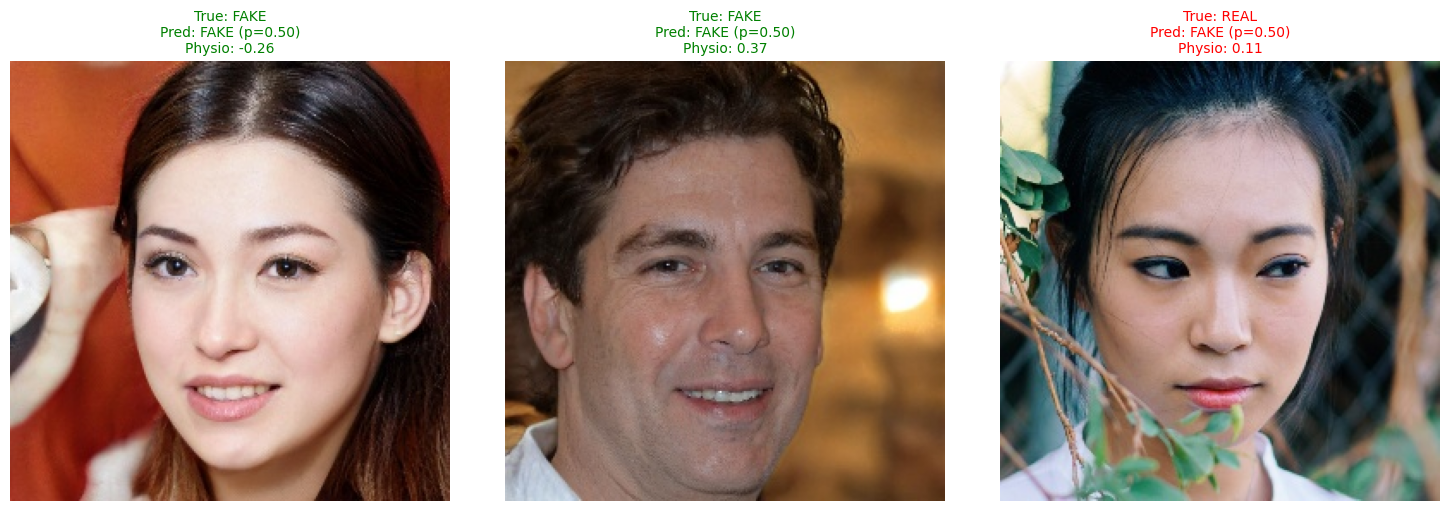

In [ ]:
import random
import matplotlib.pyplot as plt

@torch.no_grad()
def predict_single_image(model, image_path, cfg, device):
    model.eval()
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(image_path)

    left_eye, right_eye = extract_eye_crops(img, cfg)
    img_resized = cv2.resize(img, (cfg.image_size, cfg.image_size))
    img_float = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    freq_img = frequency_domain_mask(img_float, "high")
    freq_bgr = cv2.cvtColor((freq_img * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)

    batch = {
        "spatial": to_tensor_norm(img_resized).unsqueeze(0).to(device),
        "freq": to_tensor_norm(freq_bgr).unsqueeze(0).to(device),
        "left_eye": to_tensor_norm(left_eye).unsqueeze(0).to(device),
        "right_eye": to_tensor_norm(right_eye).unsqueeze(0).to(device),
    }
    outputs = model(batch)
    prob_fake = torch.sigmoid(outputs["logits"]).item()
    return {
        "probability_fake": prob_fake,
        "physiological_anomaly_score": outputs["physio_score"].item(),
        "verdict": "FAKE" if prob_fake > 0.5 else "REAL",
    }

# Let's pick 3 actual validation/test images to run inference and display
df_manifest = pd.read_csv(cfg.manifest_csv)
eval_df = df_manifest[df_manifest["predefined_split"].isin(["valid", "test"])].reset_index(drop=True)

sampled_rows = eval_df.sample(3, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for idx, (_, row) in enumerate(sampled_rows.iterrows()):
    img_path = row["image_path"]
    true_label = "FAKE" if row["label"] == 1 else "REAL"

    result = predict_single_image(model, img_path, cfg, DEVICE)

    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    axes[idx].imshow(img_rgb)
    axes[idx].axis("off")
    axes[idx].set_title(
        f"True: {true_label}\n"
        f"Pred: {result['verdict']} (p={result['probability_fake']:.2f})\n"
        f"Physio: {result['physiological_anomaly_score']:.2f}",
        fontsize=10,
        color="green" if true_label == result["verdict"] else "red"
    )

plt.tight_layout()
plt.show()

## 13. Next step: this alone does NOT test generalization

Everything above will train fast and likely get a high AUC *on 140k's own test split* --
but that number only tells you the model can tell StyleGAN from FFHQ, which is a much
narrower claim than "detects deepfakes." To actually test generalization the way the
source report defines it:

1. Add a second generator source to the manifest (e.g. DeepFakeFace, diffusion-based).
2. Set `cfg.num_nuisance_classes = 3` (real / StyleGAN / diffusion) and `cfg.alpha_mi` back
   to something like `0.3` -- with two real generator types, the DID module's adversarial
   disentanglement is doing real work again.
3. Hold one generator out entirely from training and evaluate on it alone (the zero-day
   test from the full notebook's Section 11).
4. Report that number, not just the 140k-only test AUC.

Say the word once this pipeline is running cleanly and I'll wire in that second dataset.
